In [1]:
import pandas as pd
import glob
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.signal import savgol_filter
from mpl_toolkits.mplot3d import Axes3D

In [2]:
# List all .txt files in Data folder
csv_files = glob.glob('Data/*.csv')

# read all csv inside Data folder
df = pd.concat([pd.read_csv(f, delimiter=",") for f in csv_files], ignore_index=True)

In [3]:
print("Valores únicos de Tipo de Movimento:", df['movType'].unique())
print(df.info())

Valores únicos de Tipo de Movimento: [0 1 6]
<class 'pandas.DataFrame'>
RangeIndex: 90333 entries, 0 to 90332
Data columns (total 12 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   sub      90333 non-null  int64  
 1   repID    90333 non-null  int64  
 2   movID    90333 non-null  int64  
 3   movType  90333 non-null  int64  
 4   step     90333 non-null  int64  
 5   x        90333 non-null  float64
 6   y        90333 non-null  float64
 7   z        90333 non-null  float64
 8   vel      90333 non-null  float64
 9   acc      90333 non-null  float64
 10  t        90333 non-null  float64
 11  k        90333 non-null  float64
dtypes: float64(7), int64(5)
memory usage: 8.3 MB
None


In [4]:
# Map movement types to text for easier reading
mapa_mov = {0: 'Pick', 1: 'Place', 6: 'Move'} 
df['movLabel'] = df['movType'].map(mapa_mov)

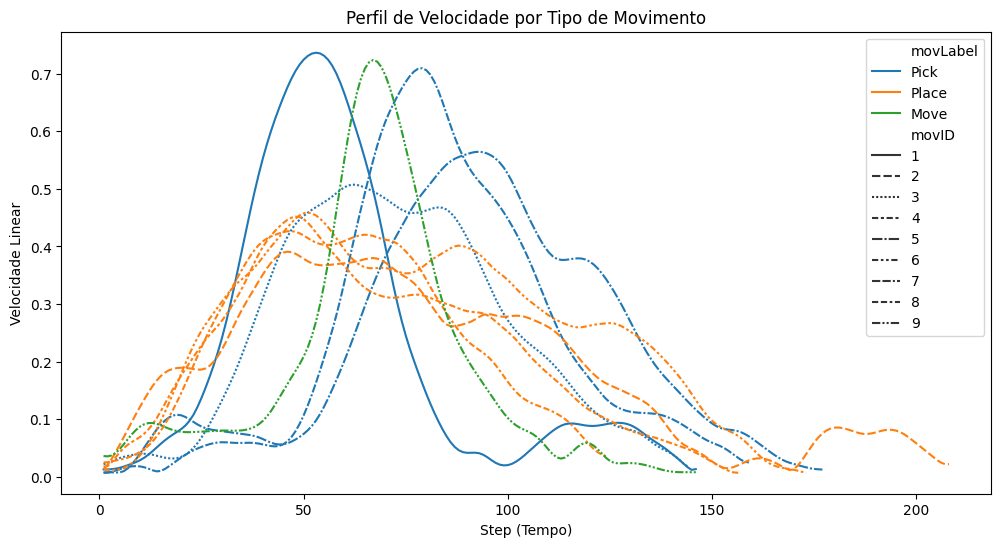

In [35]:
# --- Velocity Data Profilling (By Movement) ---
# Pega-se num sujeito e numa repetição específica para não sobrepor tudo
# Exemplo: primeiro sujeito (único) e primeira repetição (1)
exemplo = df[(df['sub'] == df['sub'].unique()[0]) & (df['repID'] == 1)]

plt.figure(figsize=(12, 6))
sns.lineplot(data=exemplo, x='step', y='vel', hue='movLabel', style='movID')
plt.title('Perfil de Velocidade por Tipo de Movimento')
plt.ylabel('Velocidade Linear')
plt.xlabel('Step (Tempo)')
plt.show()

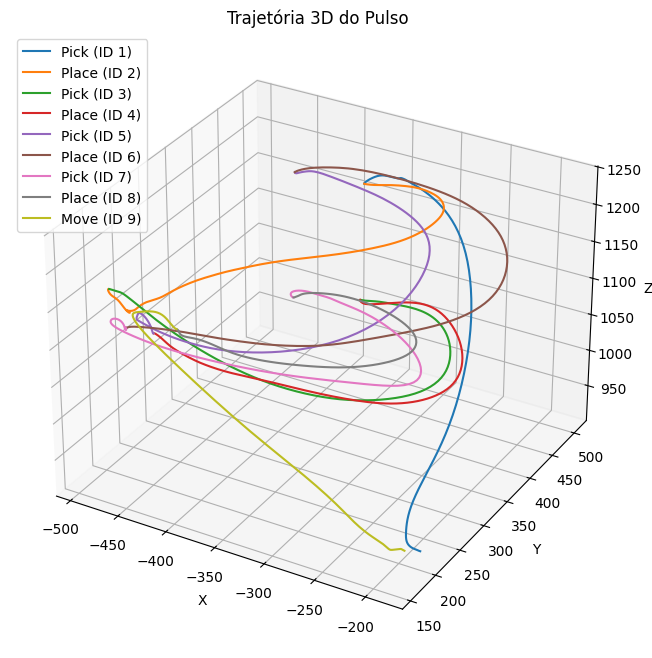

In [ ]:
# --- 3D Trajectory (By Movement) for Subject 1 ---
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Assign a different color for each movement
for movimento in exemplo['movID'].unique():
    subset = exemplo[exemplo['movID'] == movimento]
    # Choose color based on movement type
    label = subset['movLabel'].iloc[0]
    ax.plot(subset['x'], subset['y'], subset['z'], label=f"{label} (ID {movimento})")

ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_title('Trajetória 3D do Pulso for Subject 1')
ax.legend()
plt.show()

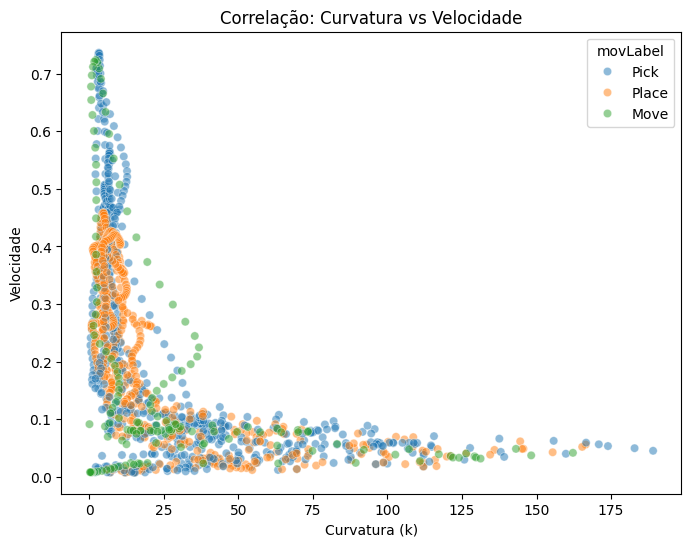

In [ ]:
# --- CURVATURE vs VELOCITY RELATIONSHIP (Two-Thirds Power Law)---
# Will velocity decrease when curvature (k) is high?
plt.figure(figsize=(8, 6))
sns.scatterplot(data=exemplo, x='k', y='vel', hue='movLabel', alpha=0.5)
plt.title('Correlação: Curvatura vs Velocidade')
plt.xlabel('Curvatura (k)')
plt.ylabel('Velocidade')
plt.show()

In [17]:
# Add Jerk to DataFrame
df["jerk"] = df.groupby(['sub', 'repID', 'movID'])['acc'].diff().fillna(0)

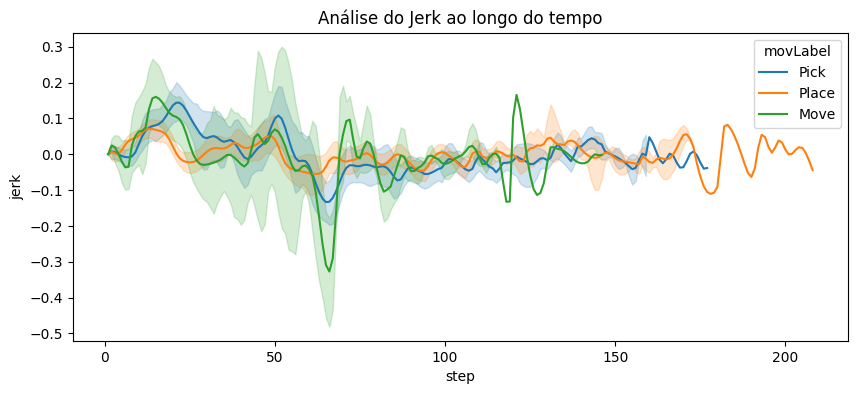

In [21]:
# --- VISUALIZE JERK OVER TIME ---
plt.figure(figsize=(10, 4))
sns.lineplot(data=df[df['sub']==df['sub'].unique()[0]], x='step', y='jerk', hue='movLabel')
plt.title('Análise do Jerk ao longo do tempo')
plt.show()

In [19]:
# SMOOTHING (Critical Step for Jerk Analysis)
# Savitzky-Golay filter is great for preserving the shape of the movement without losing real peaks
# window_length must be odd (adjust according to data frequency)
df['acc_smooth'] = savgol_filter(df['acc'], window_length=11, polyorder=2)

# CALCULATE SMOOTHED JERK
df['jerk_smooth'] = df.groupby(['sub', 'repID', 'movID'])['acc_smooth'].diff().fillna(0)

# DEFINE WHAT IS "LOW" AND "HIGH" (Percentiles)
# Let's ignore zeros and look at the absolute magnitude
jerk_values = np.abs(df['jerk_smooth'])
p25 = np.percentile(jerk_values, 25) # 25% smoothest movements
p75 = np.percentile(jerk_values, 75) # 25% with more jerks/rapid
p95 = np.percentile(jerk_values, 95) # Probably noise or impacts

print(f"Low Jerk (Smooth/Slow): < {p25:.2f}")
print(f"Medium Jerk: between {p25:.2f} and {p75:.2f}")
print(f"High Jerk (Fast/Abrupt): > {p75:.2f}")
print(f"Probable Noise: > {p95:.2f}")

Low Jerk (Smooth/Slow): < 0.03
Medium Jerk: between 0.03 and 0.15
High Jerk (Fast/Abrupt): > 0.15
Probable Noise: > 0.41


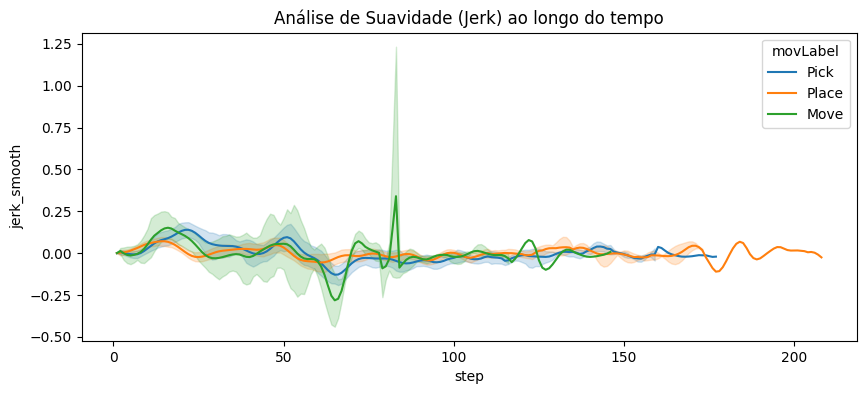

In [20]:
# --- VISUALIZE SMOOTHED JERK OVER TIME ---
plt.figure(figsize=(10, 4))
sns.lineplot(data=df[df['sub']==df['sub'].unique()[0]], x='step', y='jerk_smooth', hue='movLabel')
plt.title('Análise de Suavidade (Jerk) ao longo do tempo')
plt.show()

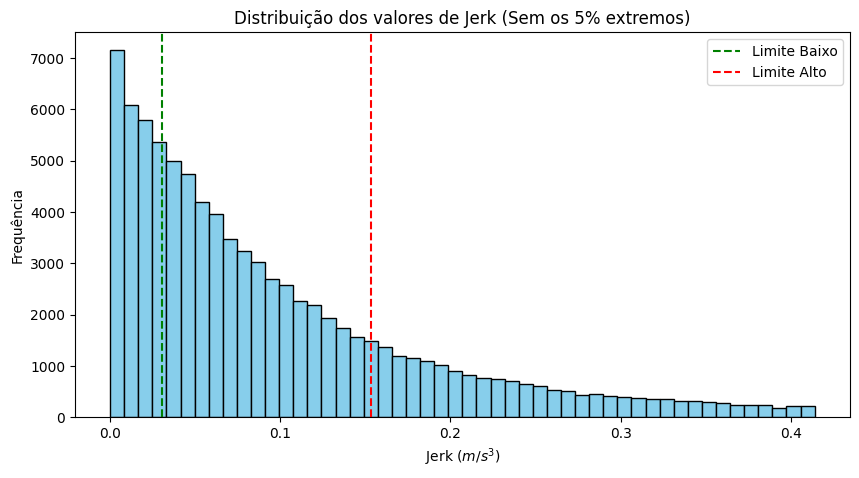

In [14]:
# VISUALIZE THE DISTRIBUTION OF JERK VALUES
plt.figure(figsize=(10, 5))
plt.hist(jerk_values[jerk_values < p95], bins=50, color='skyblue', edgecolor='black')
plt.title('Distribuição dos valores de Jerk (Sem os 5% extremos)')
plt.xlabel('Jerk ($m/s^3$)')
plt.ylabel('Frequência')
plt.axvline(p25, color='green', linestyle='--', label='Limite Baixo')
plt.axvline(p75, color='red', linestyle='--', label='Limite Alto')
plt.legend()
plt.show()

In [29]:
# FEATURE EXTRACTION For CLUSTERING
# Transform the time series into a feature table (Summary per movement)
features = df.groupby(['sub', 'repID', 'movID', 'movLabel']).agg({
    'vel': ['max', 'mean'],                        # Maximum and mean velocity
    'acc': ['max'],                                # Maximum acceleration
    'jerk_smooth': lambda x: np.mean(np.abs(x)),   # Mean absolute jerk (Overall smoothness)
    'k': 'mean',                                   # Mean curvature
    'step': 'count'                                # Movement duration (number of steps)
}).reset_index()

# Flattening column names
features.columns = ['sub', 'repID', 'movID', 'movLabel', 'Vel_Max', 'Vel_Mean', 'Acc_Max', 'Jerk_Mean', 'Curvatura_Mean', 'Duracao']

print("Table ready for Clustering:")
print(features.head())

Table ready for Clustering:
   sub  repID  movID movLabel   Vel_Max  Vel_Mean   Acc_Max  Jerk_Mean  \
0    1      1      1     Pick  0.675769  0.291690  1.896260   0.054689   
1    1      1      2    Place  0.580141  0.151339  2.820658   0.049795   
2    1      1      3     Pick  0.547964  0.237143  2.543313   0.061728   
3    1      1      4    Place  0.500931  0.254620  1.964139   0.045038   
4    1      1      5     Pick  0.711454  0.324239  2.789347   0.084999   

   Curvatura_Mean  Duracao  
0       17.145088      111  
1       30.072626      290  
2       27.444963      185  
3       21.601321      143  
4       28.206609      160  


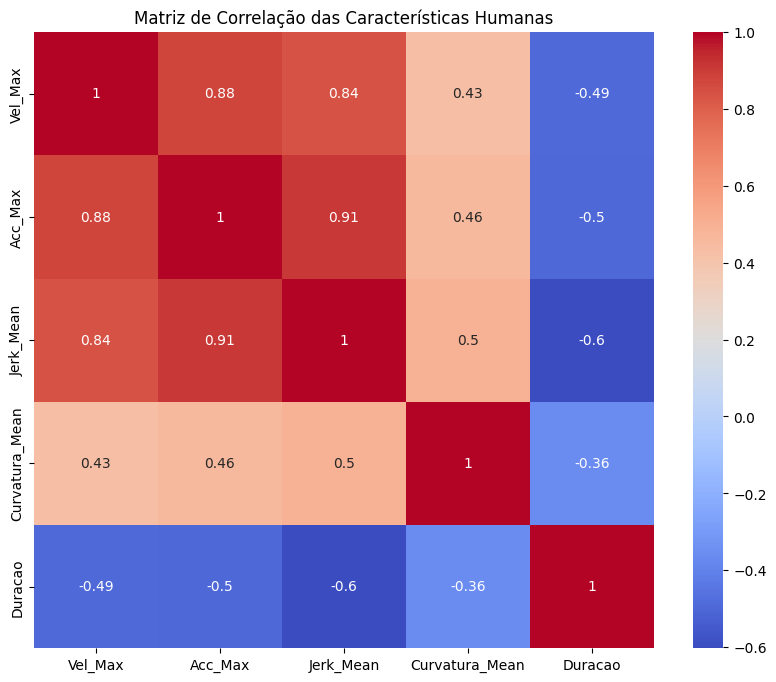

In [30]:
# Correlation (To see what influences what)
plt.figure(figsize=(10, 8))
sns.heatmap(features[['Vel_Max', 'Acc_Max', 'Jerk_Mean', 'Curvatura_Mean', 'Duracao']].corr(), annot=True, cmap='coolwarm')
plt.title('Matriz de Correlação das Características Humanas')
plt.show()